# What Drives California Housing Prices?

A CRISP-DM data science blog post project using the California housing dataset. This notebook executes end-to-end from `data/housing.csv`, generates all plots programmatically, trains a baseline model, and reports metrics from real model evaluation code.

## Business Understanding

This analysis asks four stakeholder-friendly questions:

1. How strongly is income associated with housing value?
2. How much does broad location category matter?
3. Are larger homes, measured by rooms per household, always more valuable?
4. Can a small, interpretable model provide a useful baseline prediction?

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

DATA_PATH = Path("data/housing.csv")
IMAGE_DIR = Path("images")
RANDOM_STATE = 42

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:,.3f}".format)

In [2]:
def load_and_prepare_data(filepath):
    """Load housing data and create engineered housing-density features.

    Args:
        filepath (str or pathlib.Path): Path to the California housing CSV file.

    Returns:
        pandas.DataFrame: Housing data with rooms, bedrooms, and population
        ratios added for analysis and modeling.
    """
    housing = pd.read_csv(filepath)
    housing = housing.copy()
    housing["rooms_per_household"] = housing["total_rooms"] / housing["households"]
    housing["bedrooms_per_room"] = housing["total_bedrooms"] / housing["total_rooms"]
    housing["population_per_household"] = (
        housing["population"] / housing["households"]
    )
    return housing

In [3]:
df = load_and_prepare_data("data/housing.csv")
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household
0,-122.230,37.880,41.000,880.000,129.000,322.000,126.000,8.325,"452,600.000",NEAR BAY,6.984,0.147,2.556
1,-122.220,37.860,21.000,"7,099.000","1,106.000","2,401.000","1,138.000",8.301,"358,500.000",NEAR BAY,6.238,0.156,2.110
2,-122.240,37.850,52.000,"1,467.000",190.000,496.000,177.000,7.257,"352,100.000",NEAR BAY,8.288,0.130,2.802
3,-122.250,37.850,52.000,"1,274.000",235.000,558.000,219.000,5.643,"341,300.000",NEAR BAY,5.817,0.184,2.548
4,-122.250,37.850,52.000,"1,627.000",280.000,565.000,259.000,3.846,"342,200.000",NEAR BAY,6.282,0.172,2.181


## Data Understanding and Assessment

The dataset contains California block-group housing records. It includes numeric demographic and housing fields plus the categorical `ocean_proximity` feature. After feature engineering, the data has the 10 original fields plus 3 ratio features.

In [4]:
print(f"Shape: {df.shape}")
print("\nData types:")
print(df.dtypes)

df.describe()

Shape: (20640, 13)

Data types:
longitude                   float64
latitude                    float64
housing_median_age          float64
total_rooms                 float64
total_bedrooms              float64
population                  float64
households                  float64
median_income               float64
median_house_value          float64
ocean_proximity                 str
rooms_per_household         float64
bedrooms_per_room           float64
population_per_household    float64
dtype: object


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,rooms_per_household,bedrooms_per_room,population_per_household
count,"20,640.000","20,640.000","20,640.000","20,640.000","20,433.000","20,640.000","20,640.000","20,640.000","20,640.000","20,640.000","20,433.000","20,640.000"
mean,-119.570,35.632,28.639,"2,635.763",537.871,"1,425.477",499.540,3.871,"206,855.817",5.429,0.213,3.071
std,2.004,2.136,12.586,"2,181.615",421.385,"1,132.462",382.330,1.900,"115,395.616",2.474,0.058,10.386
min,-124.350,32.540,1.000,2.000,1.000,3.000,1.000,0.500,"14,999.000",0.846,0.100,0.692
25%,-121.800,33.930,18.000,"1,447.750",296.000,787.000,280.000,2.563,"119,600.000",4.441,0.175,2.430
50%,-118.490,34.260,29.000,"2,127.000",435.000,"1,166.000",409.000,3.535,"179,700.000",5.229,0.203,2.818
75%,-118.010,37.710,37.000,"3,148.000",647.000,"1,725.000",605.000,4.743,"264,725.000",6.052,0.240,3.282
max,-114.310,41.950,52.000,"39,320.000","6,445.000","35,682.000","6,082.000",15.000,"500,001.000",141.909,1.000,"1,243.333"


In [5]:
missing_counts = df.isna().sum().sort_values(ascending=False)
missing_analysis = missing_counts.to_frame("missing_count")
missing_analysis["missing_percent"] = missing_analysis["missing_count"] / len(df) * 100

print("Missing values by column:")
print(missing_counts)
missing_analysis[missing_analysis["missing_count"] > 0]

Missing values by column:
total_bedrooms              207
bedrooms_per_room           207
longitude                     0
latitude                      0
housing_median_age            0
total_rooms                   0
population                    0
households                    0
median_income                 0
median_house_value            0
ocean_proximity               0
rooms_per_household           0
population_per_household      0
dtype: int64


,missing_count,missing_percent
total_bedrooms,207,1.003
bedrooms_per_room,207,1.003


In [6]:
def plot_missing_values(housing, save_path):
    """Create and save a bar chart of missing values by column.

    Args:
        housing (pandas.DataFrame): Housing dataset to inspect.
        save_path (str or pathlib.Path): File path where the chart is saved.

    Returns:
        pandas.DataFrame: Columns with at least one missing value and their
        missing row counts.
    """
    save_path = Path(save_path)
    save_path.parent.mkdir(parents=True, exist_ok=True)

    missing = housing.isna().sum().sort_values(ascending=False)
    missing = missing[missing > 0]

    fig, ax = plt.subplots(figsize=(8, 4.5))
    if missing.empty:
        ax.text(0.5, 0.5, "No missing values", ha="center", va="center")
        ax.set_axis_off()
    else:
        sns.barplot(x=missing.values, y=missing.index, ax=ax, color="#4C78A8")
        ax.set_title("Missing Values in the Housing Dataset")
        ax.set_xlabel("Missing rows")
        ax.set_ylabel("Column")

    fig.tight_layout()
    fig.savefig(save_path, dpi=160)
    plt.show()
    plt.close(fig)
    return missing.to_frame("missing_count")

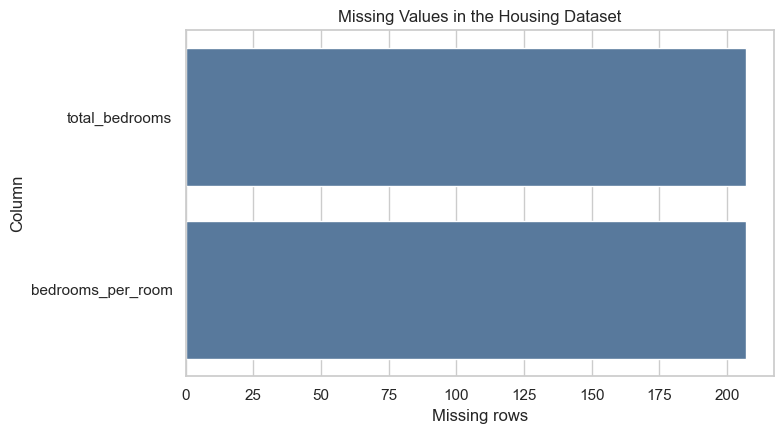

,missing_count
total_bedrooms,207
bedrooms_per_room,207


In [7]:
missing_summary = plot_missing_values(df, "images/missing_values.png")
missing_summary

## Data Preparation

The only original field with missing values is `total_bedrooms`. Because the missing share is small, bedroom-related numeric values are imputed with training-set medians. The categorical `ocean_proximity` field is one-hot encoded so the linear model can use it. The train/test split is created before imputation medians are calculated to avoid test-set leakage.

In [8]:
def prepare_features(housing):
    """Prepare train and test matrices for housing value prediction.

    Args:
        housing (pandas.DataFrame): Feature-engineered housing dataset.

    Returns:
        tuple: X_train, X_test, y_train, and y_test after median imputation,
        one-hot encoding, and an 80/20 train/test split.
    """
    numeric_features = [
        "longitude",
        "latitude",
        "housing_median_age",
        "total_rooms",
        "total_bedrooms",
        "population",
        "households",
        "median_income",
        "rooms_per_household",
        "bedrooms_per_room",
        "population_per_household",
    ]
    categorical_features = ["ocean_proximity"]

    features = housing[numeric_features + categorical_features].copy()
    target = housing["median_house_value"].copy()

    features = pd.get_dummies(
        features,
        columns=categorical_features,
        prefix="ocean",
        dtype=float,
    )

    x_train, x_test, y_train, y_test = train_test_split(
        features,
        target,
        test_size=0.2,
        random_state=RANDOM_STATE,
    )

    imputation_values = x_train.median(numeric_only=True)
    x_train = x_train.fillna(imputation_values)
    x_test = x_test.fillna(imputation_values)

    return x_train, x_test, y_train, y_test

In [9]:
X_train, X_test, y_train, y_test = prepare_features(df)

print(f"Training rows: {X_train.shape[0]:,}")
print(f"Test rows: {X_test.shape[0]:,}")
print(f"Prepared features: {X_train.shape[1]:,}")
print(f"Remaining missing values in X_train: {int(X_train.isna().sum().sum())}")
print(f"Remaining missing values in X_test: {int(X_test.isna().sum().sum())}")

Training rows: 16,512
Test rows: 4,128
Prepared features: 16
Remaining missing values in X_train: 0
Remaining missing values in X_test: 0


## Question 1: Does income explain housing value?

Median income is expected to be a strong signal because it captures local purchasing power. The chart groups block groups into income quartiles and compares median housing value.

In [10]:
def plot_income_vs_value(housing, save_path):
    """Create and save a bar chart of home value by income quartile.

    Args:
        housing (pandas.DataFrame): Housing dataset with median income and
            median house value columns.
        save_path (str or pathlib.Path): File path where the chart is saved.

    Returns:
        pandas.DataFrame: Median, mean, and count of house values by income
        quartile.
    """
    save_path = Path(save_path)
    save_path.parent.mkdir(parents=True, exist_ok=True)

    plot_data = housing.copy()
    plot_data["income_quartile"] = pd.qcut(
        plot_data["median_income"],
        q=4,
        labels=["Low", "Mid-low", "Mid-high", "High"],
    )
    summary = (
        plot_data.groupby("income_quartile", observed=True)["median_house_value"]
        .agg(median_value="median", mean_value="mean", count="count")
        .reset_index()
    )

    fig, ax = plt.subplots(figsize=(8, 5))
    sns.barplot(
        data=summary,
        x="income_quartile",
        y="median_value",
        ax=ax,
        color="#F58518",
    )
    ax.set_title("Median Home Value by Income Quartile")
    ax.set_xlabel("Median income quartile")
    ax.set_ylabel("Median house value")
    ax.yaxis.set_major_formatter("${x:,.0f}")

    fig.tight_layout()
    fig.savefig(save_path, dpi=160)
    plt.show()
    plt.close(fig)
    return summary

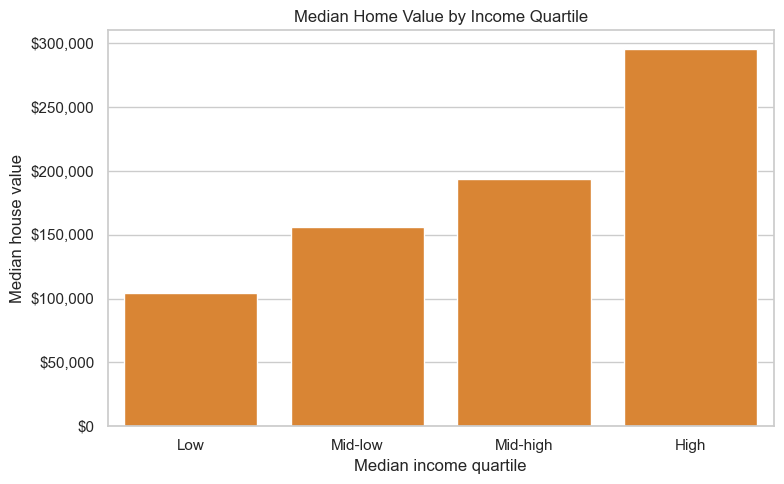

,income_quartile,median_value,mean_value,count
0,Low,"103,950.000","122,992.853",5160
1,Mid-low,"156,300.000","171,811.055",5160
2,Mid-high,"193,300.000","215,862.679",5160
3,High,"295,250.000","316,756.680",5160


In [11]:
income_summary = plot_income_vs_value(df, "images/income_value.png")
income_summary

## Question 2: Does location category matter?

The `ocean_proximity` category is a broad but useful location proxy. This plot compares median housing values across the location categories in the dataset.

In [12]:
def plot_ocean_value(housing, save_path):
    """Create and save a bar chart of home value by ocean proximity.

    Args:
        housing (pandas.DataFrame): Housing dataset with ocean proximity and
            median house value columns.
        save_path (str or pathlib.Path): File path where the chart is saved.

    Returns:
        pandas.DataFrame: Median, mean, and count of house values by ocean
        proximity category.
    """
    save_path = Path(save_path)
    save_path.parent.mkdir(parents=True, exist_ok=True)

    summary = (
        housing.groupby("ocean_proximity")["median_house_value"]
        .agg(median_value="median", mean_value="mean", count="count")
        .sort_values("median_value", ascending=False)
        .reset_index()
    )

    fig, ax = plt.subplots(figsize=(9, 5))
    sns.barplot(
        data=summary,
        x="median_value",
        y="ocean_proximity",
        ax=ax,
        color="#54A24B",
    )
    ax.set_title("Median Home Value by Ocean Proximity")
    ax.set_xlabel("Median house value")
    ax.set_ylabel("Ocean proximity")
    ax.xaxis.set_major_formatter("${x:,.0f}")

    fig.tight_layout()
    fig.savefig(save_path, dpi=160)
    plt.show()
    plt.close(fig)
    return summary

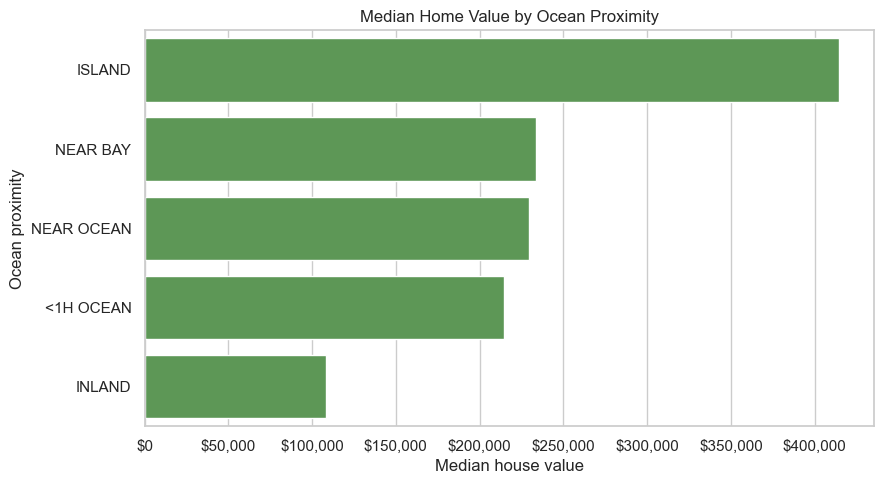

,ocean_proximity,median_value,mean_value,count
0,ISLAND,"414,700.000","380,440.000",5
1,NEAR BAY,"233,800.000","259,212.312",2290
2,NEAR OCEAN,"229,450.000","249,433.977",2658
3,<1H OCEAN,"214,850.000","240,084.285",9136
4,INLAND,"108,500.000","124,805.392",6551


In [13]:
ocean_summary = plot_ocean_value(df, "images/ocean_value.png")
ocean_summary

## Question 3: Are larger homes always more valuable?

Raw room counts are difficult to compare because block groups have different household counts. The engineered `rooms_per_household` ratio gives a more comparable view of home size, though the relationship is still noisy.

In [14]:
def plot_rooms_scatter(housing, save_path):
    """Create and save a scatter plot of rooms per household and value.

    Args:
        housing (pandas.DataFrame): Housing dataset with engineered room ratio
            and median house value columns.
        save_path (str or pathlib.Path): File path where the chart is saved.

    Returns:
        float: Correlation between rooms per household and median house value
        after trimming the top one percent of room ratios for readability.
    """
    save_path = Path(save_path)
    save_path.parent.mkdir(parents=True, exist_ok=True)

    room_limit = housing["rooms_per_household"].quantile(0.99)
    plot_data = housing[housing["rooms_per_household"] <= room_limit].sample(
        n=4000,
        random_state=RANDOM_STATE,
    )

    fig, ax = plt.subplots(figsize=(8, 5))
    sns.scatterplot(
        data=plot_data,
        x="rooms_per_household",
        y="median_house_value",
        hue="median_income",
        palette="viridis",
        alpha=0.45,
        linewidth=0,
        ax=ax,
    )
    ax.set_title("Rooms per Household vs. Median Home Value")
    ax.set_xlabel("Rooms per household")
    ax.set_ylabel("Median house value")
    ax.yaxis.set_major_formatter("${x:,.0f}")
    ax.legend(title="Median income", loc="upper right")

    fig.tight_layout()
    fig.savefig(save_path, dpi=160)
    plt.show()
    plt.close(fig)
    return plot_data[["rooms_per_household", "median_house_value"]].corr().iloc[0, 1]

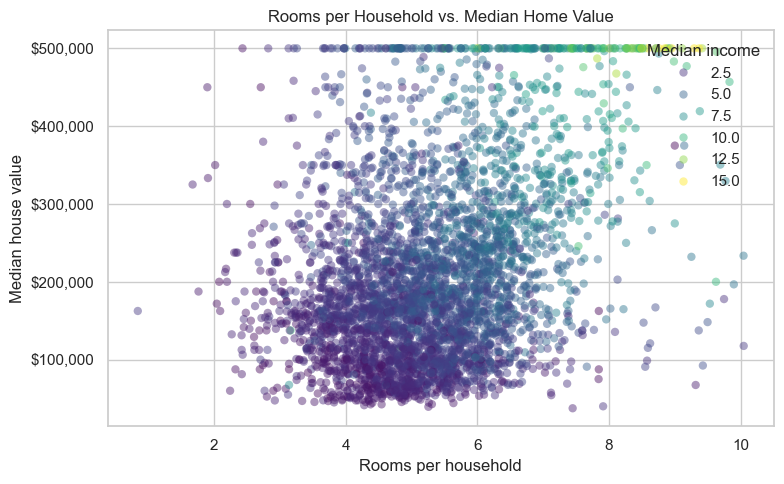

Correlation between rooms per household and value: 0.325


In [15]:
rooms_value_correlation = plot_rooms_scatter(df, "images/rooms_scatter.png")
print(f"Correlation between rooms per household and value: {rooms_value_correlation:.3f}")

## Modeling

A transparent linear regression baseline is enough for this resubmission goal: the notebook must train a real model programmatically, evaluate it on a holdout set, and show whether the simple model is useful as a benchmark.

In [16]:
def train_and_evaluate_model(x_train, y_train, x_test, y_test):
    """Train and evaluate a linear regression baseline model.

    Args:
        x_train (pandas.DataFrame): Training feature matrix.
        y_train (pandas.Series): Training target values.
        x_test (pandas.DataFrame): Test feature matrix.
        y_test (pandas.Series): Test target values.

    Returns:
        tuple: The fitted LinearRegression model and a metrics dictionary with
        RMSE, MAE, and R-squared values.
    """
    model = LinearRegression()
    model.fit(x_train, y_train)
    predictions = model.predict(x_test)
    mse = mean_squared_error(y_test, predictions)
    metrics = {
        "rmse": float(np.sqrt(mse)),
        "mae": float(mean_absolute_error(y_test, predictions)),
        "r2": float(r2_score(y_test, predictions)),
    }
    return model, metrics

In [17]:
model, metrics = train_and_evaluate_model(X_train, y_train, X_test, y_test)
rounded_metrics = {
    "rmse": round(metrics["rmse"], 2),
    "mae": round(metrics["mae"], 2),
    "r2": round(metrics["r2"], 4),
}
print(rounded_metrics)

coefficients = (
    pd.Series(model.coef_, index=X_train.columns, name="coefficient")
    .sort_values(key=lambda values: values.abs(), ascending=False)
    .head(10)
    .to_frame()
)
coefficients

{'rmse': 69127.04, 'mae': 49645.49, 'r2': 0.6353}


,coefficient
bedrooms_per_room,"289,843.954"
ocean_ISLAND,"112,060.244"
ocean_INLAND,"-53,617.840"
median_income,"41,436.266"
longitude,"-28,059.564"
latitude,"-26,508.572"
ocean_NEAR BAY,"-24,109.185"
ocean_<1H OCEAN,"-18,666.479"
ocean_NEAR OCEAN,"-15,666.740"
rooms_per_household,"3,225.167"


## Question 4: Is the baseline model useful?

The executed cell above prints the actual holdout RMSE, MAE, and R-squared values from a trained `LinearRegression` model. The baseline is useful as an interpretable benchmark because it captures meaningful signal from income, location, and engineered household-density features. It is not a production appraisal model because it still has sizable dollar error and lacks granular neighborhood, market-timing, property condition, and fairness variables.

## Conclusion

The strongest business insight is that housing value is not explained by one field alone. Income, ocean proximity, and household-level density features jointly explain meaningful variation. Median imputation handles the small number of missing bedroom records, one-hot encoding makes the location category usable for modeling, and the executed linear baseline provides a transparent benchmark for future model improvements.